# Function 1 - Week 5: Model Predictions

#### Diagnostic Model Comparisons through Week 4 return, received on **23 October 2026**; the saved Week 5 coverage query is retained.

In [1]:
# Imports and shared helpers.
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
from IPython.display import display

shared_dir = next(
    (folder / "Shared" for folder in (Path.cwd(), *Path.cwd().parents)
     if (folder / "Shared" / "model_review_helpers.py").is_file()), None,
)
if shared_dir is None:
    raise FileNotFoundError("Run from this notebook's folder inside notebooks/.")
if str(shared_dir) not in sys.path:
    sys.path.insert(0, str(shared_dir))

function_shared_dir = shared_dir.parent / "Function_1" / "FunctionSpecificShared"
if str(function_shared_dir) not in sys.path:
    sys.path.insert(0, str(function_shared_dir))

from exploration_review_helpers import load_exploration_review, remaining_exploration_queries
from model_helpers import make_models
from model_review_helpers import review_latest_predictions
from query_budget import remaining_queries
from function_1_model_helpers import (
    run_target_reviews, summarise_target_reviews, save_target_model_views,
)

In [2]:
# Settings for this run. Both targets retain the fixed height scale used previously.
FUNCTION_NUMBER = 1
CURRENT_WEEK = 5
INPUT_COLUMNS = ["x1", "x2"]
OUTPUT_COLUMN = "y"
EXPECTED_ROUND_COUNTS = {0: 10, 1: 1, 2: 1, 3: 1, 4: 1}
ANALYSIS_DIR = Path.cwd().resolve()
WEEK_DIR = ANALYSIS_DIR.parent
DATA_PATH = ANALYSIS_DIR / "observations.csv"
FIGURES_DIR = ANALYSIS_DIR / "figures"
TITLE = f"Function {FUNCTION_NUMBER} - Week {CURRENT_WEEK}"
PORTAL_DECIMALS = 6
FIRST_PLAN_WEEK = 2
PLANNED_QUERIES = pd.DataFrame([
    [0.15308205385104573, 0.13395525138390008],
    [0.7818589422435338, 0.0256071460565101],
    [0.12954929624948736, 0.822189245547224],
    [0.9121401448788213, 0.8617829948823881],
], columns=INPUT_COLUMNS)
HEIGHT_SCALE = 1e-200
TARGET_LABELS = {"signed": "signed-log height h", "magnitude": "log-magnitude activity g"}
GP_LENGTH_SCALES = {"GP: local (l=0.15)": 0.15, "GP: broad (l=0.35)": 0.35}
GP_NAMES = list(GP_LENGTH_SCALES)
MODEL_SETTINGS = dict(ridge_alpha=1.0, quadratic_degree=2,
                      noise_fraction=0.10, gp_length_scales=GP_LENGTH_SCALES)
SELECTION_METRIC = "LOO MAE"
CANDIDATE_SETTINGS = dict(power=12, seed=42, precision=PORTAL_DECIMALS, include_corners=True)
EXPLORATION_WEIGHT = 1.96
EXPLORATION_WEIGHTS = (0.0, 1.0, 1.96, 3.0)
GRID_SIDE = 61

In [3]:
# Load the measured snapshot and retain the actual saved coverage query.
review = load_exploration_review(
    DATA_PATH, input_columns=INPUT_COLUMNS, output_column=OUTPUT_COLUMN,
    expected_round_counts=EXPECTED_ROUND_COUNTS,
)
inputs = review["inputs"].to_numpy(dtype=float)
raw_y = review["outputs"].to_numpy(dtype=float)
anchor = inputs[int(np.argmax(raw_y))].copy()
remaining_plan = remaining_exploration_queries(
    PLANNED_QUERIES, current_week=CURRENT_WEEK, first_plan_week=FIRST_PLAN_WEEK, precision=PORTAL_DECIMALS,
)
planned_point = remaining_plan.loc[CURRENT_WEEK, INPUT_COLUMNS].to_numpy(dtype=float).round(PORTAL_DECIMALS)
planned_portal_input = remaining_plan.loc[CURRENT_WEEK, "Portal input"]
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
display(remaining_plan)

,x1,x2,Portal input
Week,,,
5,0.91214,0.861783,0.912140-0.861783


In [4]:
# Refit signed and magnitude targets separately, using the same declared models and candidates.
models = make_models(**MODEL_SETTINGS)
RUN_SETTINGS = dict(input_columns=INPUT_COLUMNS, height_scale=HEIGHT_SCALE, gp_names=GP_NAMES,
    selection_metric=SELECTION_METRIC, candidate_settings=CANDIDATE_SETTINGS,
    weight=EXPLORATION_WEIGHT, weights=EXPLORATION_WEIGHTS)
study = run_target_reviews(models, inputs, raw_y, planned_point, **RUN_SETTINGS)
for target_name, model_run in study["runs"].items():
    display(pd.Series({"Target units": TARGET_LABELS[target_name], "Selected GP": model_run["selected_name"]}))
    display(model_run["table"].round(3))

Target units    signed-log height h
Selected GP      GP: local (l=0.15)
dtype: str

,Model,Training MAE,LOO MAE,LOO RMSE,MAE / baseline,RMSE reduction (%)
0,Quadratic ridge,79.486,106.756,135.322,0.797,7.744
1,Linear ridge,90.365,110.077,135.665,0.822,7.510
2,GP: local (l=0.15),3.081,110.872,138.517,0.828,5.566
3,Mean baseline,124.312,133.875,146.681,1.000,0.000
4,GP: broad (l=0.35),29.074,143.763,173.666,1.074,-18.397


Target units    log-magnitude activity g
Selected GP           GP: broad (l=0.35)
dtype: str

,Model,Training MAE,LOO MAE,LOO RMSE,MAE / baseline,RMSE reduction (%)
0,GP: broad (l=0.35),2.639,22.289,30.612,0.448,50.378
1,GP: local (l=0.15),0.384,29.118,45.795,0.586,25.769
2,Quadratic ridge,21.641,32.434,43.995,0.653,28.686
3,Linear ridge,38.271,49.556,69.242,0.997,-12.238
4,Mean baseline,46.153,49.704,61.692,1.000,0.000


In [5]:
# Retrospective checks in transformed target units, with the latest result held out.
for target_name, model_run in study["runs"].items():
    latest_review = review_latest_predictions(model_run["predictions"], study["targets"][target_name], review["latest_mask"])
    display(pd.Series({"Target units": TARGET_LABELS[target_name]}))
    display(latest_review.drop(columns=["Latest absolute error (%)", "Latest share of squared error (%)"]).round(3))

Target units    signed-log height h
dtype: str

,Model,Latest held-out prediction,Latest error,Other rows LOO RMSE
0,Mean baseline,17.478,46.458,151.671
1,Linear ridge,60.249,89.228,138.594
2,GP: local (l=0.15),67.231,96.211,141.247
3,Quadratic ridge,134.416,163.396,132.917
4,GP: broad (l=0.35),332.616,361.596,149.740


Target units    log-magnitude activity g
dtype: str

,Model,Latest held-out prediction,Latest error,Other rows LOO RMSE
0,GP: broad (l=0.35),88.902,59.922,27.074
1,Quadratic ridge,122.709,93.729,37.532
2,GP: local (l=0.15),124.065,95.086,39.535
3,Mean baseline,131.718,102.738,57.330
4,Linear ridge,183.623,154.643,57.651


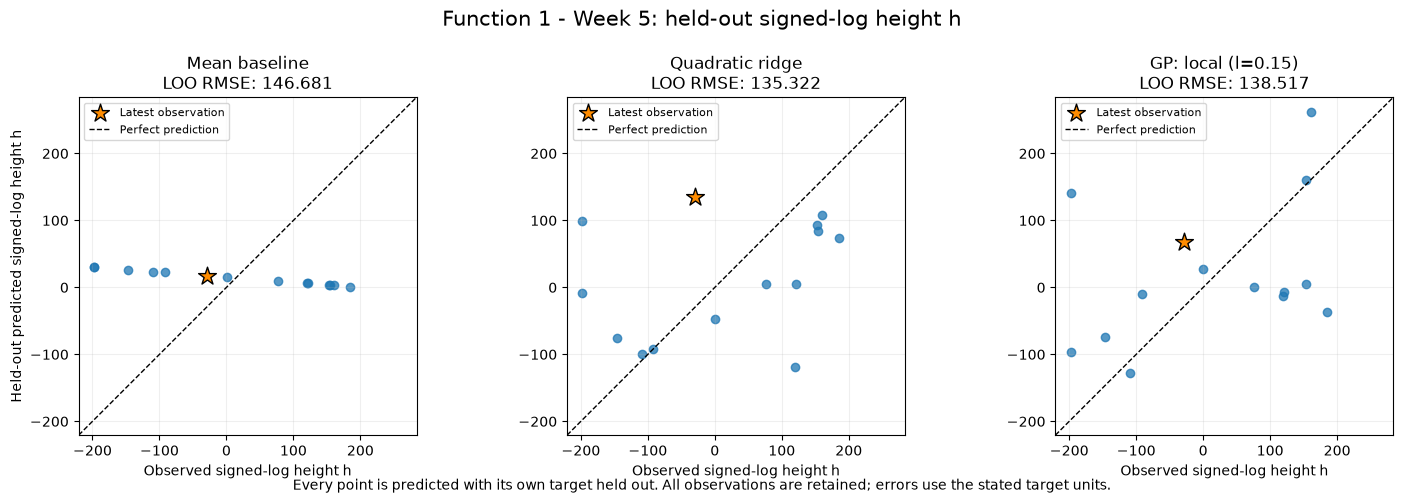

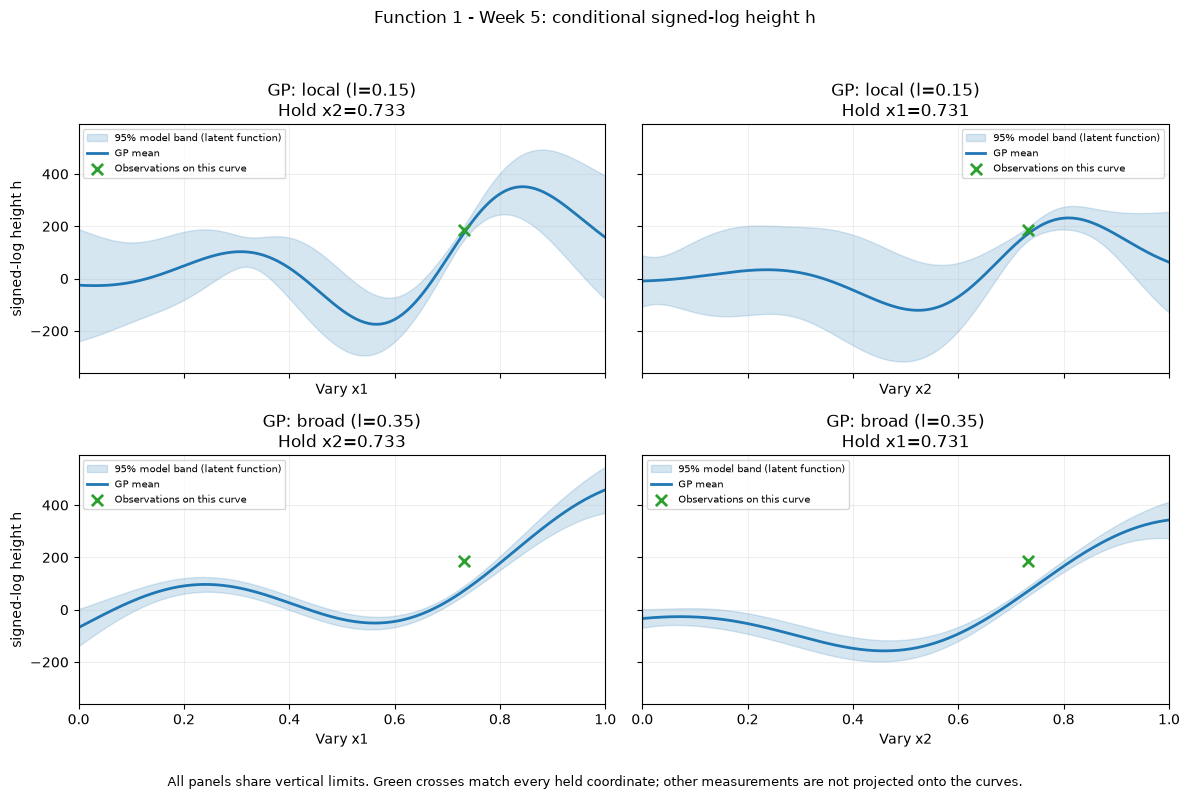

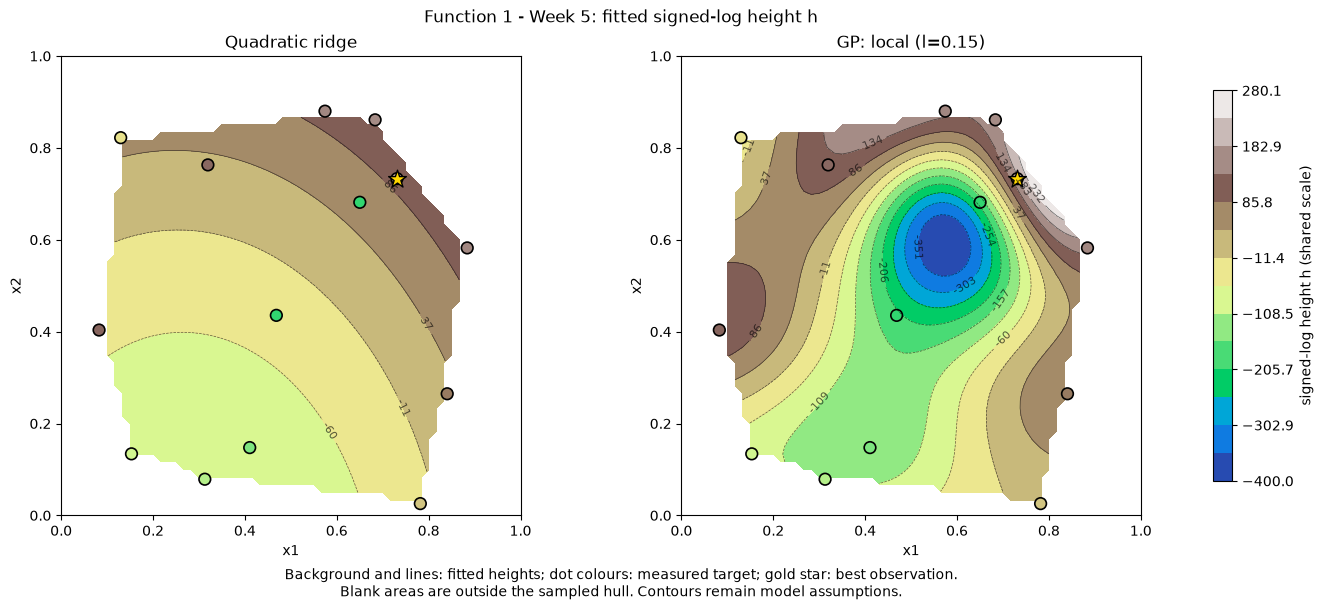

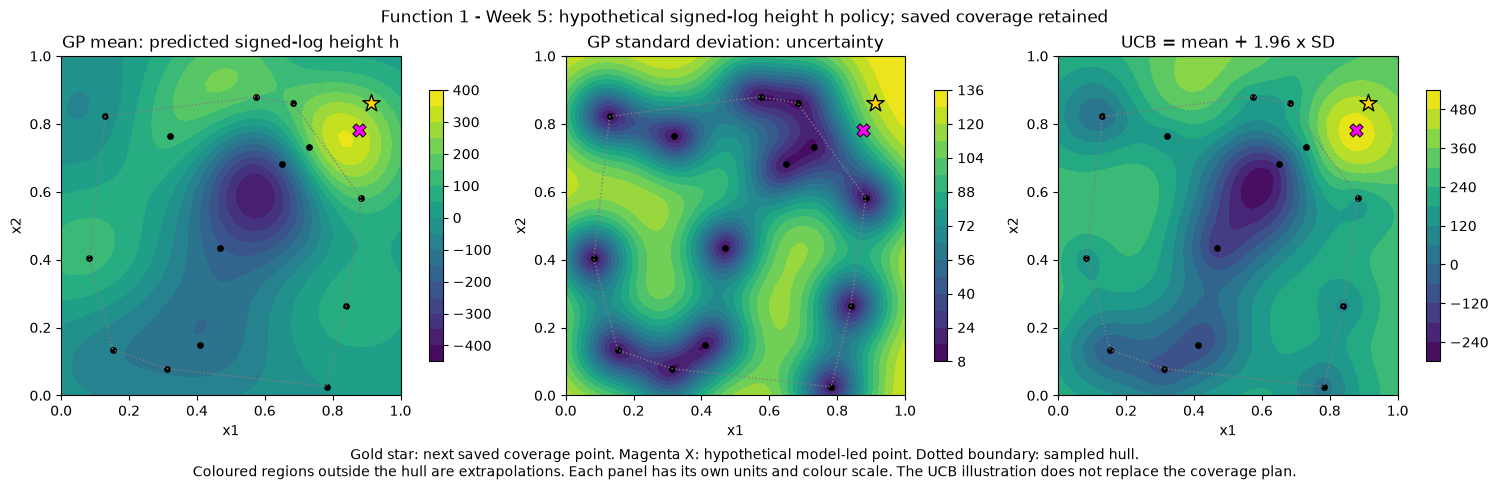

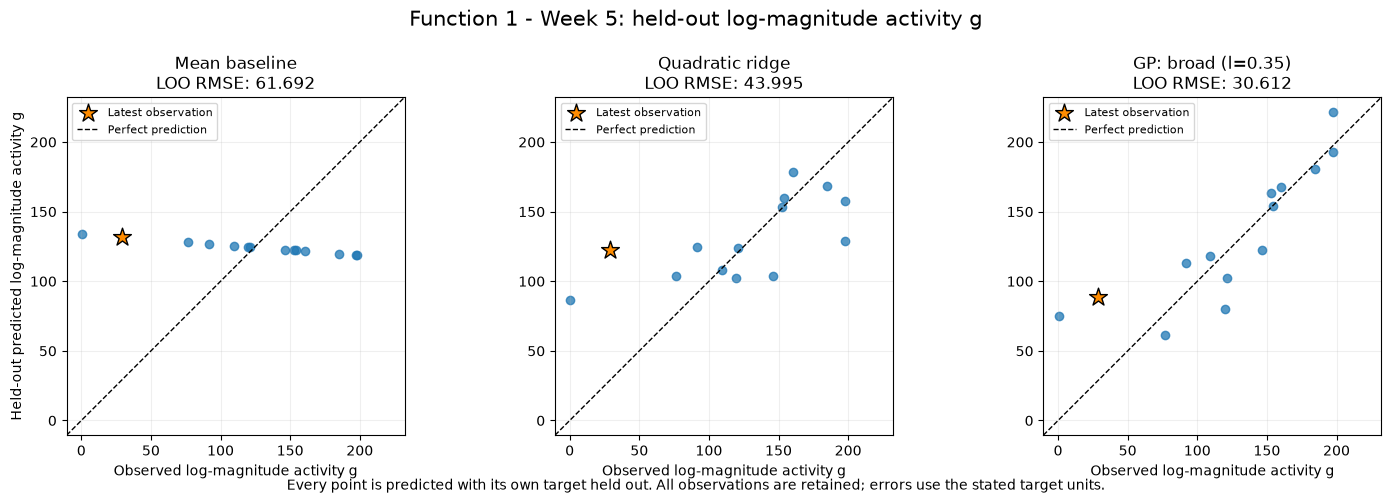

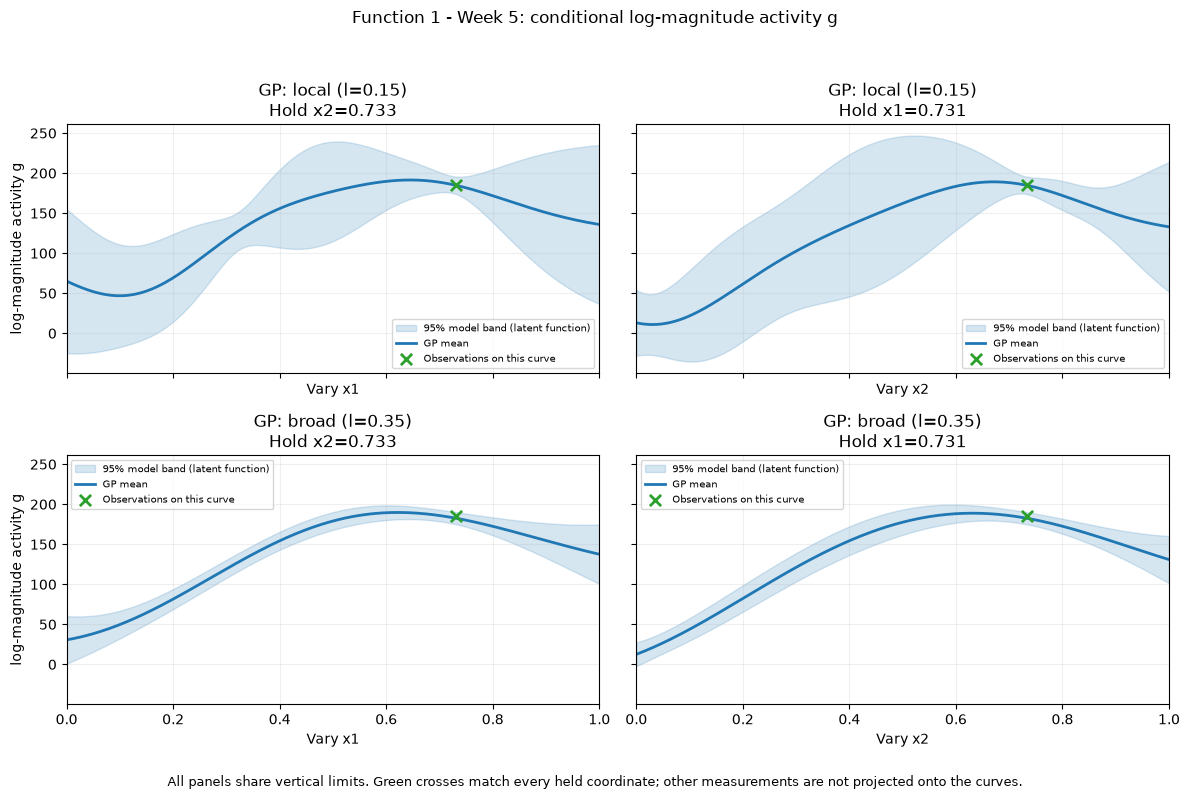

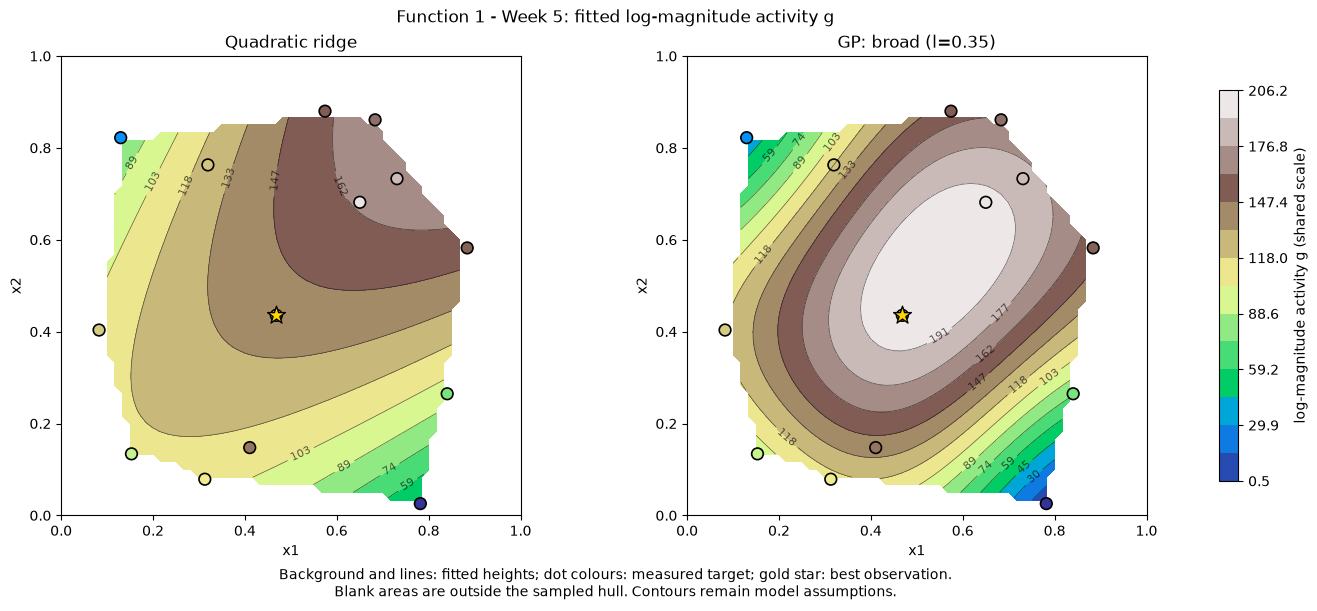

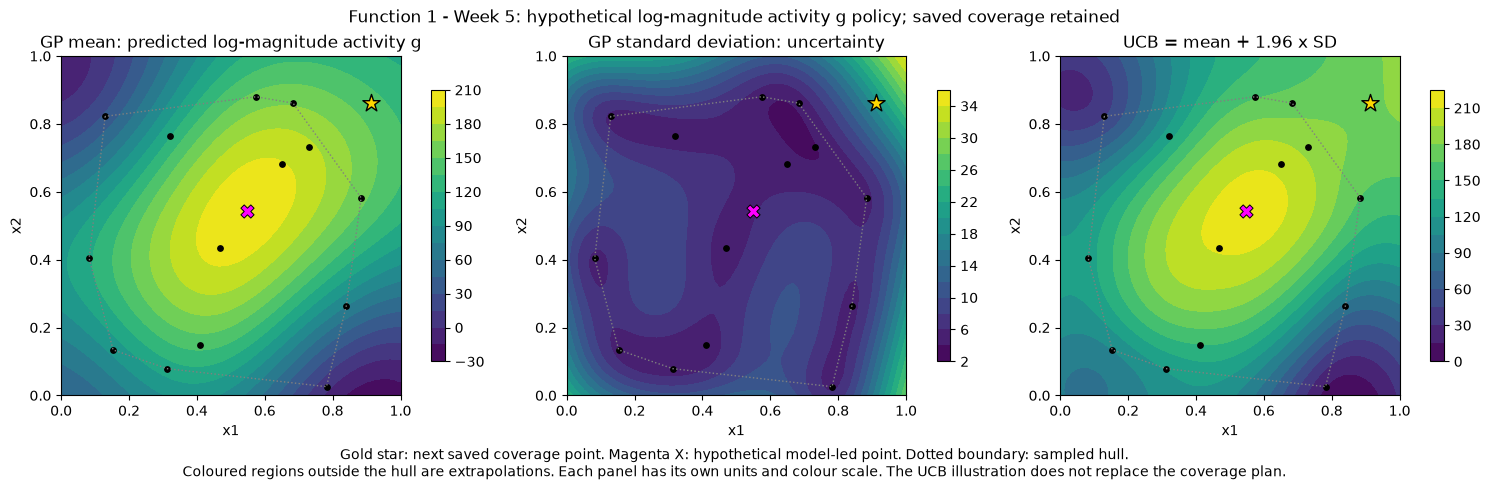

In [6]:
# Export both model explanations with labelled units; the gold query marker is the saved plan.
figures = save_target_model_views(
    study, inputs, anchor, planned_point, review["latest_mask"], input_columns=INPUT_COLUMNS,
    gp_names=GP_NAMES, target_labels=TARGET_LABELS, title=TITLE,
    figures_dir=FIGURES_DIR, grid_side=GRID_SIDE, weight=EXPLORATION_WEIGHT,
)
display(*figures)

In [7]:
# All model-led alternatives are hypothetical. The actual planned point is scored separately.
target_summaries = summarise_target_reviews(study, target_labels=TARGET_LABELS)
for target_name in TARGET_LABELS:
    display(pd.Series({"Target units": TARGET_LABELS[target_name], "Saved portal input": planned_portal_input}))
    display(pd.DataFrame({"Saved coverage": study["planned_predictions"][target_name],
                          "Hypothetical model policy": study["proposals"][target_name]}))
    display(study["gp_sensitivity"][target_name].round(6))

Target units          signed-log height h
Saved portal input      0.912140-0.861783
dtype: str

,Saved coverage,Hypothetical model policy
point,"[0.91214, 0.861783]","[0.876772, 0.780703]"
predicted_output,197.992918,327.572147
posterior_std,120.647711,93.589865
ucb,434.462432,511.008282
predicted_mean_improvement,13.105815,142.685043
inside_sampled_hull,False,False
portal_input,0.912140-0.861783,0.876772-0.780703


,GP,Weight,x1,x2,Predicted output,Posterior SD
0,GP: local (l=0.15),0.00,0.842297,0.758028,356.046995,69.947531
1,GP: local (l=0.15),1.00,0.858588,0.752755,351.139746,77.095702
2,GP: local (l=0.15),1.96,0.876772,0.780703,327.572147,93.589865
3,GP: local (l=0.15),3.00,0.892267,0.794645,300.414910,103.428001
4,GP: broad (l=0.35),0.00,0.999926,0.920712,534.027320,71.623128
5,GP: broad (l=0.35),1.00,0.999926,0.920712,534.027320,71.623128
6,GP: broad (l=0.35),1.96,0.996987,0.942501,530.521590,74.064177
7,GP: broad (l=0.35),3.00,0.999999,0.999999,510.499815,82.652033


Target units          log-magnitude activity g
Saved portal input           0.912140-0.861783
dtype: str

,Saved coverage,Hypothetical model policy
point,"[0.91214, 0.861783]","[0.548112, 0.542075]"
predicted_output,140.557871,206.195203
posterior_std,19.129499,5.825968
ucb,178.051689,217.6141
predicted_mean_improvement,-57.183229,8.454103
inside_sampled_hull,False,True
portal_input,0.912140-0.861783,0.548112-0.542075


,GP,Weight,x1,x2,Predicted output,Posterior SD
0,GP: local (l=0.15),0.00,0.623818,0.640871,198.344834,12.926780
1,GP: local (l=0.15),1.00,0.503847,0.572445,195.124551,32.595954
2,GP: local (l=0.15),1.96,0.473500,0.605968,188.709142,37.121456
3,GP: local (l=0.15),3.00,0.648284,0.479293,175.149437,43.469165
4,GP: broad (l=0.35),0.00,0.538485,0.538884,206.211458,5.742480
5,GP: broad (l=0.35),1.00,0.548112,0.542075,206.195203,5.825968
6,GP: broad (l=0.35),1.96,0.548112,0.542075,206.195203,5.825968
7,GP: broad (l=0.35),3.00,0.571219,0.535763,205.471842,6.137931


In [8]:
# Preserve the decision status separately from both transformed-target policies.
analysis_summary = {
    "function": FUNCTION_NUMBER, "week": CURRENT_WEEK, "analysis": "function_1_target_review",
    "observations": len(raw_y), "decision_policy": "retained_fixed_coverage_plan",
    "planned_portal_input": planned_portal_input, "planned_point": planned_point.tolist(),
    "proposal_status": "saved_plan_retained_not_submitted_here",
    "height_scale": HEIGHT_SCALE, "model_settings": MODEL_SETTINGS,
    "candidate_settings": CANDIDATE_SETTINGS, "best_signed_output": float(raw_y.max()),
    "target_reviews": target_summaries, "remaining_queries": remaining_queries(WEEK_DIR),
}
print(json.dumps(analysis_summary, indent=2))

{
  "function": 1,
  "week": 5,
  "analysis": "function_1_target_review",
  "observations": 14,
  "decision_policy": "retained_fixed_coverage_plan",
  "planned_portal_input": "0.912140-0.861783",
  "planned_point": [
    0.91214,
    0.861783
  ],
  "proposal_status": "saved_plan_retained_not_submitted_here",
  "height_scale": 1e-200,
  "model_settings": {
    "ridge_alpha": 1.0,
    "quadratic_degree": 2,
    "noise_fraction": 0.1,
    "gp_length_scales": {
      "GP: local (l=0.15)": 0.15,
      "GP: broad (l=0.35)": 0.35
    }
  },
  "candidate_settings": {
    "power": 12,
    "seed": 42,
    "precision": 6,
    "include_corners": true
  },
  "best_signed_output": 7.710875114502849e-16,
  "target_reviews": {
    "signed": {
      "target_units": "signed-log height h",
      "selected_model": "GP: local (l=0.15)",
      "selection_metric": "LOO MAE",
      "selected_mae": 110.87168929512087,
      "baseline_mae": 133.87458229226655,
      "selected_rmse": 138.51695557652914,
      "